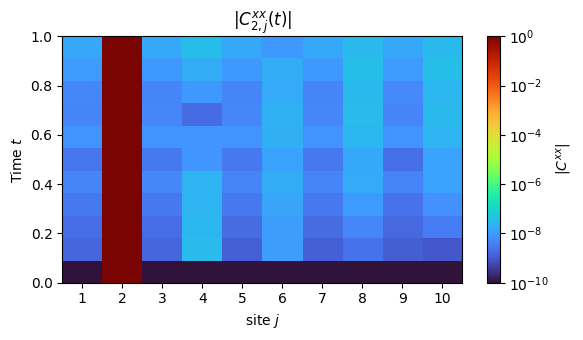

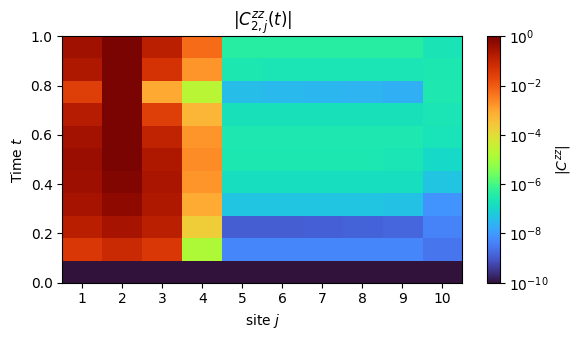

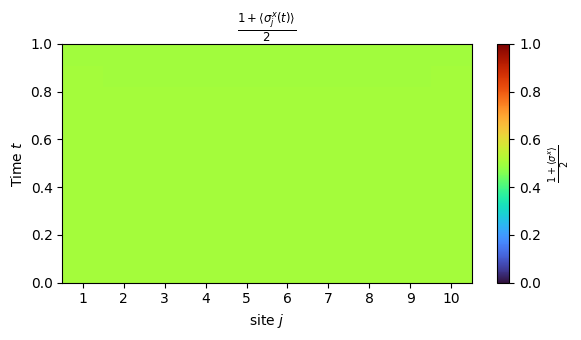

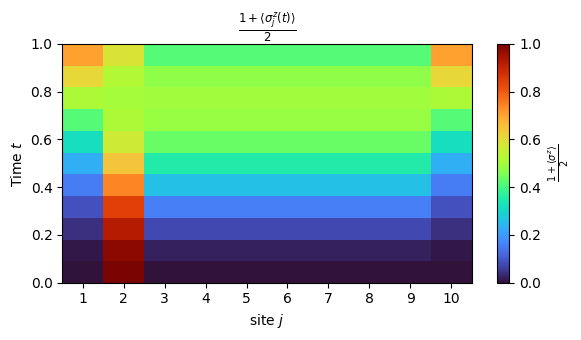

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os

valuesList = [1]

# -------------------------
# CREATE OUTPUT DIR
# -------------------------
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

for value in valuesList:
    # -------------------------
    # SETTINGS
    # -------------------------
    outdir = "ED_Data/Trial/"
    i0 = 1
    t_max_plot = 1
    alpha = 0
    N = 10
    Bx = 0.1
    Jx = 0
    Jz = 1

    vmin_corr = 1e-10
    prefix=f"Bx{Bx}Jz{Jz}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")
    df_magx = pd.read_csv(f"{outdir}/{prefix}magx.csv")
    df_magz = pd.read_csv(f"{outdir}/{prefix}magz.csv")

    # -------------------------
    # TIME AXIS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    # -------------------------
    # BUILD CORRELATION MATRIX
    # -------------------------
    def build_corr_matrix(df, prefix_str):
        C_cols = [c for c in df.columns if c.startswith(f"{prefix_str}_{i0}_")]
        if len(C_cols) == 0:
            raise ValueError(f"No correlation columns found for {prefix_str}")

        j_vals = np.array([int(c.split("_")[-1]) for c in C_cols])
        order = np.argsort(j_vals)

        mat = np.abs(df[C_cols].values[:, order])
        mat = np.clip(mat, vmin_corr, 1.0)
        mat = mat[mask, :]

        return mat, j_vals[order]

    # -------------------------
    # BUILD MAGNETIZATION MATRIX
    # -------------------------
    def build_mag_matrix(df, prefix_str):
        m_cols = [c for c in df.columns if c.startswith(f"{prefix_str}_")]
        if len(m_cols) == 0:
            raise ValueError(f"No magnetization columns found for {prefix_str}")

        j_vals = np.array([int(c.split("_")[-1]) for c in m_cols])
        order = np.argsort(j_vals)

        mat = df[m_cols].values[:, order]
        mat = mat[mask, :]

        return mat, j_vals[order]

    CorrXX, j_vals_corr = build_corr_matrix(df_xx, "Cxx")
    CorrZZ, _           = build_corr_matrix(df_zz, "Czz")

    MagX, j_vals_magx = build_mag_matrix(df_magx, "mx")
    MagZ, j_vals_magz = build_mag_matrix(df_magz, "mz")

    # -------------------------
    # NORMALIZE (-1,1) → (0,1)
    # -------------------------
    MagZ = (MagZ + 1) / 2
    MagX = (MagX + 1) / 2

    # -------------------------
    # EXTENTS (FOR SITES 1..N)
    # -------------------------
    extent_corr = [0.5, N + 0.5, t_min, t_max]
    extent_magx = [0.5, N + 0.5, t_min, t_max]
    extent_magz = [0.5, N + 0.5, t_min, t_max]

    xticks = np.arange(1, N + 1)

    # =========================
    # PLOT XX
    # =========================
    fig, ax = plt.subplots(figsize=(6, 3.5))

    im = ax.imshow(
        CorrXX,
        origin="lower",
        aspect="auto",
        cmap="turbo",
        interpolation="nearest",
        norm=mcolors.LogNorm(vmin=vmin_corr, vmax=1),
        extent=extent_corr,
    )

    ax.set_title(rf"$|C^{{xx}}_{{{i0+1},j}}(t)|$")
    ax.set_ylabel(r"Time $t$")
    ax.set_xlabel(r"site $j$")
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)

    plt.colorbar(im, ax=ax, label=r"$|C^{xx}|$")
    plt.tight_layout()

    filename = f"{plot_dir}/{prefix}_Cxx_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    # =========================
    # PLOT ZZ
    # =========================
    fig, ax = plt.subplots(figsize=(6, 3.5))

    im = ax.imshow(
        CorrZZ,
        origin="lower",
        aspect="auto",
        cmap="turbo",
        interpolation="nearest",
        norm=mcolors.LogNorm(vmin=vmin_corr, vmax=1),
        extent=extent_corr,
    )

    ax.set_title(rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$")
    ax.set_ylabel(r"Time $t$")
    ax.set_xlabel(r"site $j$")
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)

    plt.colorbar(im, ax=ax, label=r"$|C^{zz}|$")
    plt.tight_layout()

    filename = f"{plot_dir}/{prefix}_Czz_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    # =========================
    # PLOT MAGX
    # =========================
    fig, ax = plt.subplots(figsize=(6, 3.5))

    im = ax.imshow(
        MagX,
        origin="lower",
        aspect="auto",
        cmap="turbo",
        interpolation="nearest",
        vmin=0,
        vmax=1.0,
        extent=extent_magx,
    )

    ax.set_title(r"$\frac{1+\langle \sigma_j^x(t)\rangle}{2}$")
    ax.set_ylabel(r"Time $t$")
    ax.set_xlabel(r"site $j$")
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)

    plt.colorbar(im, ax=ax, label=r"$\frac{1+\langle \sigma^x\rangle}{2}$")
    plt.tight_layout()

    filename = f"{plot_dir}/{prefix}_MagX_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    # =========================
    # PLOT MAGZ
    # =========================
    fig, ax = plt.subplots(figsize=(6, 3.5))

    im = ax.imshow(
        MagZ,
        origin="lower",
        aspect="auto",
        cmap="turbo",
        interpolation="nearest",
        vmin=0,
        vmax=1.0,
        extent=extent_magz,
    )

    ax.set_title(r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$")
    ax.set_ylabel(r"Time $t$")
    ax.set_xlabel(r"site $j$")
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)

    plt.colorbar(im, ax=ax, label=r"$\frac{1+\langle \sigma^z\rangle}{2}$")
    plt.tight_layout()

    filename = f"{plot_dir}/{prefix}_MagZ_i{i0+1}_alpha{alpha}_Jx{Jx}_Bz{Bx}_Jz{Jz}.pdf"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

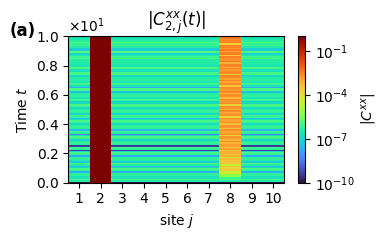

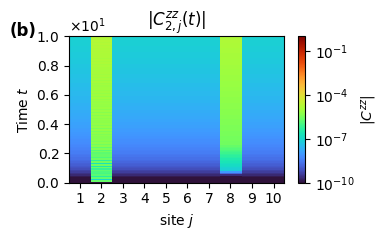

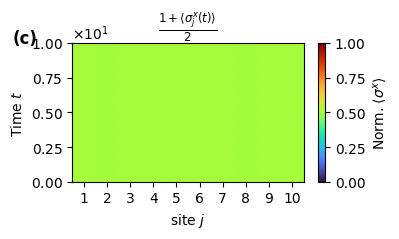

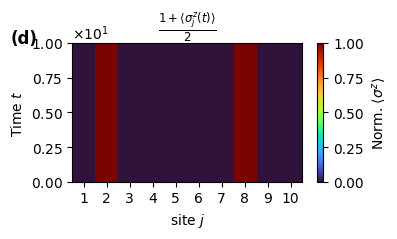

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
from matplotlib.ticker import ScalarFormatter

# -------------------------
# FORMATTING & SETUP
# -------------------------
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# Create output directory
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

savefig = True
valuesList = [1]

for value in valuesList:
    # -------------------------
    # SETTINGS & PATHS
    # -------------------------
    outdir = "ED_Data/Confinement"
    i0 = 1
    t_max_plot = 1000
    alpha = 0
    N = 10
    Bx = 0.1
    Jx = 0
    Jz = 20

    vmin_corr = 1e-10
    prefix = f"Bx{Bx}Jz{Jz}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")
    df_magx = pd.read_csv(f"{outdir}/{prefix}magx.csv")
    df_magz = pd.read_csv(f"{outdir}/{prefix}magz.csv")

    # -------------------------
    # DATA PROCESSING FUNCTIONS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    def build_matrix(df, prefix_str, is_corr=True):
        cols = [c for c in df.columns if c.startswith(prefix_str)]
        if len(cols) == 0:
            raise ValueError(f"No columns found for {prefix_str}")
        
        # Sort by site index j
        j_vals = np.array([int(c.split("_")[-1]) for c in cols])
        order = np.argsort(j_vals)
        
        mat = df[cols].values[:, order]
        if is_corr:
            mat = np.abs(mat)
            mat = np.clip(mat, vmin_corr, 1.0)
        
        return mat[mask, :], j_vals[order]

    # Process matrices
    CorrXX, _ = build_matrix(df_xx, f"Cxx_{i0}_", is_corr=True)
    CorrZZ, _ = build_matrix(df_zz, f"Czz_{i0}_", is_corr=True)
    MagX, _   = build_matrix(df_magx, "mx_", is_corr=False)
    MagZ, _   = build_matrix(df_magz, "mz_", is_corr=False)

    # Normalize Magnetization (-1,1) → (0,1)
    MagX = (MagX + 1) / 2
    MagZ = (MagZ + 1) / 2

    # -------------------------
    # PLOTTING LOOP
    # -------------------------
    # Configuration list for each panel
    plot_configs = [
        {
            "data": CorrXX, 
            "title": rf"$|C^{{xx}}_{{{i0+1},j}}(t)|$", 
            "label": r"$|C^{xx}|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Cxx", 
            "letter": "(a)"
        },
        {
            "data": CorrZZ, 
            "title": rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
            "label": r"$|C^{zz}|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Czz", 
            "letter": "(b)"
        },
        {
            "data": MagX, 
            "title": r"$\frac{1+\langle \sigma_j^x(t)\rangle}{2}$", 
            "label": r"Norm. $\langle \sigma^x \rangle$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagX", 
            "letter": "(c)"
        },
        {
            "data": MagZ, 
            "title": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
            "label": r"Norm. $\langle \sigma^z \rangle$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagZ", 
            "letter": "(d)"
        }
    ]

    for cfg in plot_configs:
        fig, ax = plt.subplots(figsize=(4, 2.5))
        
        im = ax.imshow(
            cfg["data"],
            origin="lower",
            aspect="auto",
            cmap="turbo",
            interpolation="nearest",
            norm=cfg["norm"],
            extent=[0.5, N + 0.5, t_min, t_max],
        )

        # Panel Lettering
        # x=-0.15 relative to axis width, y=1.1 relative to axis height
        ax.text(-0.15, 1.1, cfg["letter"], transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='top', ha='right')

        ax.set_title(cfg["title"])
        ax.set_ylabel(r"Time $t$")
        ax.set_xlabel(r"site $j$")
        
        # Formatting Axis
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
        ax.set_xticks(np.arange(1, N + 1))
        
        # Colorbar
        plt.colorbar(im, ax=ax, label=cfg["label"])
        plt.tight_layout()

        if savefig:
            full_path = f"{plot_dir}/{prefix}_{cfg['fname']}_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
            plt.savefig(full_path, dpi=300, bbox_inches="tight")
        
        plt.show()

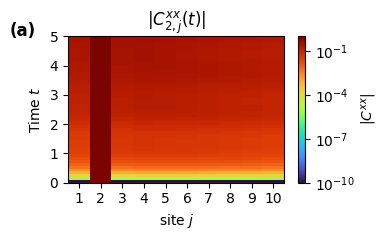

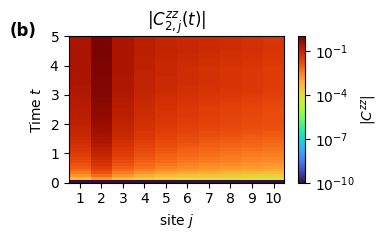

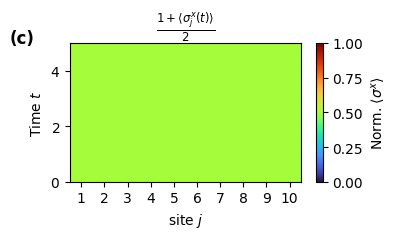

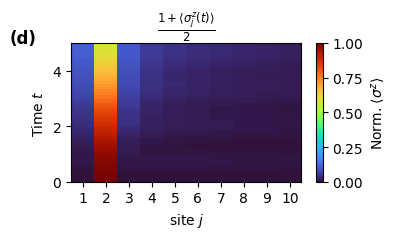

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
from matplotlib.ticker import ScalarFormatter

# -------------------------
# FORMATTING & SETUP
# -------------------------
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# Create output directory
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

savefig = True
valuesList = [1]

for value in valuesList:
    # -------------------------
    # SETTINGS & PATHS
    # -------------------------
    outdir = "ED_Data/Trial/"
    i0 = 1
    t_max_plot = 5
    alpha = 0
    N = 10
    Bz = 1
    Jx = 0.1
    Jz = 0

    vmin_corr = 1e-10
    prefix = f"Bz{Bz}Jx{Jx}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")
    df_magx = pd.read_csv(f"{outdir}/{prefix}magx.csv")
    df_magz = pd.read_csv(f"{outdir}/{prefix}magz.csv")

    # -------------------------
    # DATA PROCESSING FUNCTIONS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    def build_matrix(df, prefix_str, is_corr=True):
        cols = [c for c in df.columns if c.startswith(prefix_str)]
        if len(cols) == 0:
            raise ValueError(f"No columns found for {prefix_str}")
        
        # Sort by site index j
        j_vals = np.array([int(c.split("_")[-1]) for c in cols])
        order = np.argsort(j_vals)
        
        mat = df[cols].values[:, order]
        if is_corr:
            mat = np.abs(mat)
            mat = np.clip(mat, vmin_corr, 1.0)
        
        return mat[mask, :], j_vals[order]

    # Process matrices
    CorrXX, _ = build_matrix(df_xx, f"Cxx_{i0}_", is_corr=True)
    CorrZZ, _ = build_matrix(df_zz, f"Czz_{i0}_", is_corr=True)
    MagX, _   = build_matrix(df_magx, "mx_", is_corr=False)
    MagZ, _   = build_matrix(df_magz, "mz_", is_corr=False)

    # Normalize Magnetization (-1,1) → (0,1)
    MagX = (MagX + 1) / 2
    MagZ = (MagZ + 1) / 2

    # -------------------------
    # PLOTTING LOOP
    # -------------------------
    # Configuration list for each panel
    plot_configs = [
        {
            "data": CorrXX, 
            "title": rf"$|C^{{xx}}_{{{i0+1},j}}(t)|$", 
            "label": r"$|C^{xx}|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Cxx", 
            "letter": "(a)"
        },
        {
            "data": CorrZZ, 
            "title": rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
            "label": r"$|C^{zz}|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Czz", 
            "letter": "(b)"
        },
        {
            "data": MagX, 
            "title": r"$\frac{1+\langle \sigma_j^x(t)\rangle}{2}$", 
            "label": r"Norm. $\langle \sigma^x \rangle$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagX", 
            "letter": "(c)"
        },
        {
            "data": MagZ, 
            "title": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
            "label": r"Norm. $\langle \sigma^z \rangle$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagZ", 
            "letter": "(d)"
        }
    ]

    for cfg in plot_configs:
        fig, ax = plt.subplots(figsize=(4, 2.5))
        
        im = ax.imshow(
            cfg["data"],
            origin="lower",
            aspect="auto",
            cmap="turbo",
            interpolation="nearest",
            norm=cfg["norm"],
            extent=[0.5, N + 0.5, t_min, t_max],
        )

        # Panel Lettering
        # x=-0.15 relative to axis width, y=1.1 relative to axis height
        ax.text(-0.15, 1.1, cfg["letter"], transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='top', ha='right')

        ax.set_title(cfg["title"])
        ax.set_ylabel(r"Time $t$")
        ax.set_xlabel(r"site $j$")
        
        # Formatting Axis
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
        ax.set_xticks(np.arange(1, N + 1))
        
        # Colorbar
        plt.colorbar(im, ax=ax, label=cfg["label"])
        plt.tight_layout()

        if savefig:
            full_path = f"{plot_dir}/{prefix}_{cfg['fname']}_i{i0+1}_alpha{alpha}_Jx{Jx}_Bz{Bz}_Jz{Jz}.pdf"
            plt.savefig(full_path, dpi=300, bbox_inches="tight")
        
        plt.show()

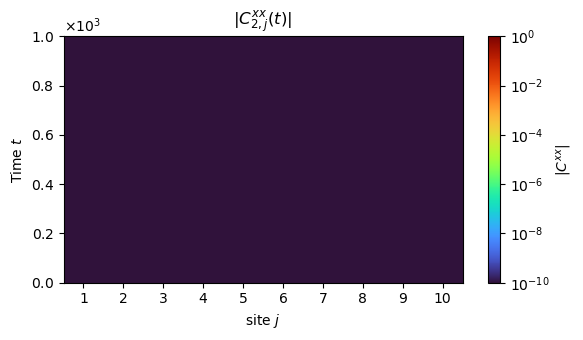

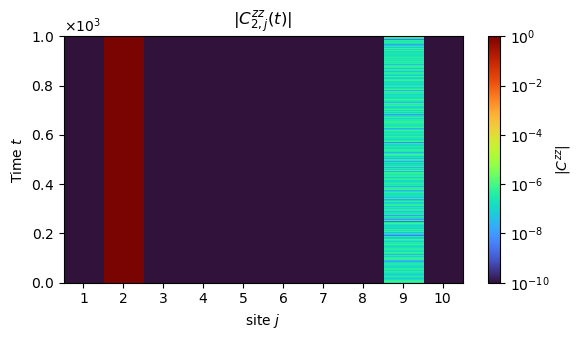

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

valuesList = [1]

# -------------------------
# CREATE OUTPUT DIR
# -------------------------
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

savefig=True

for value in valuesList:
    # -------------------------
    # SETTINGS
    # -------------------------
    outdir = "ED_Data/Confinement/"
    i0 = 1
    t_max_plot = 1000
    alpha = 0
    N = 10
    Bz = 0
    Jx = 20
    Jz = 0

    vmin_corr = 1e-10
    prefix = f"Bz{Bz}Jx{Jx}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")

    # -------------------------
    # TIME AXIS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    # -------------------------
    # BUILD CORRELATION MATRIX
    # -------------------------
    def build_corr_matrix(df, prefix_str):
        C_cols = [c for c in df.columns if c.startswith(f"{prefix_str}_{i0}_")]
        if len(C_cols) == 0:
            raise ValueError(f"No correlation columns found for {prefix_str}")

        j_vals = np.array([int(c.split("_")[-1]) for c in C_cols])
        order = np.argsort(j_vals)

        mat = np.abs(df[C_cols].values[:, order])
        mat = np.clip(mat, vmin_corr, 1.0)
        mat = mat[mask, :]

        return mat, j_vals[order]


    CorrXX, j_vals_corr = build_corr_matrix(df_xx, "Cxx")
    CorrZZ, _           = build_corr_matrix(df_zz, "Czz")

    # -------------------------
    # EXTENTS (FOR SITES 1..N)
    # -------------------------
    extent_corr = [0.5, N + 0.5, t_min, t_max]

    xticks = np.arange(1, N + 1)

    # =========================
    # PLOT XX
    # =========================
    fig, ax = plt.subplots(figsize=(6, 3.5))

    im = ax.imshow(
        CorrXX,
        origin="lower",
        aspect="auto",
        cmap="turbo",
        interpolation="nearest",
        norm=mcolors.LogNorm(vmin=vmin_corr, vmax=1),
        extent=extent_corr,
    )

    ax.set_title(rf"$|C^{{xx}}_{{{i0+1},j}}(t)|$")
    ax.set_ylabel(r"Time $t$")
    ax.set_xlabel(r"site $j$")
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)

    plt.colorbar(im, ax=ax, label=r"$|C^{xx}|$")
    plt.tight_layout()

    filename = f"{plot_dir}/{prefix}_Cxx_i{i0+1}_alpha{alpha}_Jx{Jx}_Bz{Bz}_Jz{Jz}.pdf"

    if savefig==True:
        plt.savefig(filename, dpi=300, bbox_inches="tight") 
    plt.show()

    # =========================
    # PLOT ZZ
    # =========================
    fig, ax = plt.subplots(figsize=(6, 3.5))

    im = ax.imshow(
        CorrZZ,
        origin="lower",
        aspect="auto",
        cmap="turbo",
        interpolation="nearest",
        norm=mcolors.LogNorm(vmin=vmin_corr, vmax=1),
        extent=extent_corr,
    )

    ax.set_title(rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$")
    ax.set_ylabel(r"Time $t$")
    ax.set_xlabel(r"site $j$")
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)

    plt.colorbar(im, ax=ax, label=r"$|C^{zz}|$")
    plt.tight_layout()

    filename = f"{plot_dir}/{prefix}_Czz_i{i0+1}_alpha{alpha}_Jx{Jx}_Bz{Bz}_Jz{Jz}.pdf"

    if savefig==True:
        plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

## Confinement

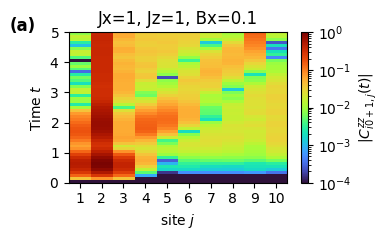

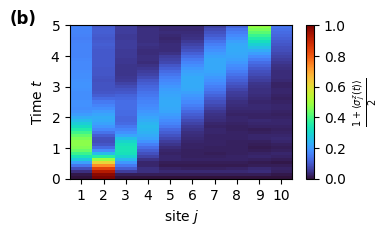

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
from matplotlib.ticker import ScalarFormatter

# -------------------------
# FORMATTING & SETUP
# -------------------------
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# Create output directory
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

savefig = True
valuesList = [1]

for value in valuesList:
    # -------------------------
    # SETTINGS & PATHS
    # -------------------------
    outdir = "ED_Data/Confinement/"
    i0 = 1
    t_max_plot = 1000
    alpha = 0
    N = 10
    Bx = 0.1
    Jx = 1
    Jz = 1

    vmin_corr = 1e-4
    prefix = f"Bx{Bx}Jz{Jz}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")
    df_magx = pd.read_csv(f"{outdir}/{prefix}magx.csv")
    df_magz = pd.read_csv(f"{outdir}/{prefix}magz.csv")

    # -------------------------
    # DATA PROCESSING FUNCTIONS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    def build_matrix(df, prefix_str, is_corr=True):
        cols = [c for c in df.columns if c.startswith(prefix_str)]
        if len(cols) == 0:
            raise ValueError(f"No columns found for {prefix_str}")
        
        # Sort by site index j
        j_vals = np.array([int(c.split("_")[-1]) for c in cols])
        order = np.argsort(j_vals)
        
        mat = df[cols].values[:, order]
        if is_corr:
            mat = np.abs(mat)
            mat = np.clip(mat, vmin_corr, 1.0)
        
        return mat[mask, :], j_vals[order]

    # Process matrices
    CorrXX, _ = build_matrix(df_xx, f"Cxx_{i0}_", is_corr=True)
    CorrZZ, _ = build_matrix(df_zz, f"Czz_{i0}_", is_corr=True)
    MagX, _   = build_matrix(df_magx, "mx_", is_corr=False)
    MagZ, _   = build_matrix(df_magz, "mz_", is_corr=False)

    # Normalize Magnetization (-1,1) → (0,1)
    MagX = (MagX + 1) / 2
    MagZ = (MagZ + 1) / 2

    # -------------------------
    # PLOTTING LOOP
    # -------------------------
    # Configuration list for each panel
    plot_configs = [
        {
            "data": CorrZZ, 
            "title": rf"Jx={Jx}, Jz={Jz}, Bx={Bx}", 
            "label": r"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Czz", 
            "letter": "(a)"
        },
        # {
        #     "data": CorrZZ, 
        #     "title": rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
        #     "label": r"$|C^{zz}|$", 
        #     "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
        #     "fname": "Czz", 
        #     "letter": "(b)"
        # },
        {
            "data": MagZ, 
            "title": r"", 
            "label": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagZ", 
            "letter": "(b)"
        },
        # {
        #     "data": MagZ, 
        #     "title": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
        #     "label": r"Norm. $\langle \sigma^z \rangle$", 
        #     "norm": plt.Normalize(0, 1), 
        #     "fname": "MagZ", 
        #     "letter": "(d)"
        # }
    ]

    for cfg in plot_configs:
        fig, ax = plt.subplots(figsize=(4, 2.5))
        
        im = ax.imshow(
            cfg["data"],
            origin="lower",
            aspect="auto",
            cmap="turbo",
            interpolation="nearest",
            norm=cfg["norm"],
            extent=[0.5, N + 0.5, t_min, t_max],
        )

        # Panel Lettering
        # x=-0.15 relative to axis width, y=1.1 relative to axis height
        ax.text(-0.15, 1.1, cfg["letter"], transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='top', ha='right')

        ax.set_title(cfg["title"])
        ax.set_ylabel(r"Time $t$")
        ax.set_xlabel(r"site $j$")
        
        # Formatting Axis
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
        ax.set_xticks(np.arange(1, N + 1))
        
        # Colorbar
        plt.colorbar(im, ax=ax, label=cfg["label"])
        plt.tight_layout()

        if savefig:
            full_path = f"{plot_dir}/{prefix}_{cfg['fname']}_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
            plt.savefig(full_path, dpi=300, bbox_inches="tight")
        
        # plt.savefig("plt/ConfinementJx1.pdf")
        plt.show()

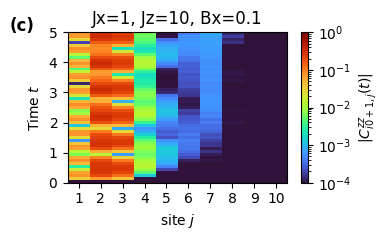

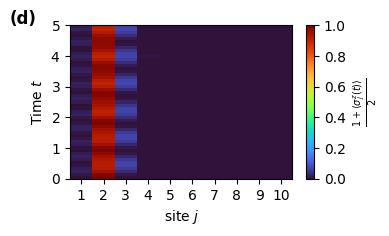

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
from matplotlib.ticker import ScalarFormatter

# -------------------------
# FORMATTING & SETUP
# -------------------------
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# Create output directory
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

savefig = True
valuesList = [1]

for value in valuesList:
    # -------------------------
    # SETTINGS & PATHS
    # -------------------------
    outdir = "ED_Data/Confinement/"
    i0 = 1
    t_max_plot = 1000
    alpha = 0
    N = 10
    Bx = 0.1
    Jx = 1
    Jz = 10

    vmin_corr = 1e-4
    prefix = f"Bx{Bx}Jz{Jz}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")
    df_magx = pd.read_csv(f"{outdir}/{prefix}magx.csv")
    df_magz = pd.read_csv(f"{outdir}/{prefix}magz.csv")

    # -------------------------
    # DATA PROCESSING FUNCTIONS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    def build_matrix(df, prefix_str, is_corr=True):
        cols = [c for c in df.columns if c.startswith(prefix_str)]
        if len(cols) == 0:
            raise ValueError(f"No columns found for {prefix_str}")
        
        # Sort by site index j
        j_vals = np.array([int(c.split("_")[-1]) for c in cols])
        order = np.argsort(j_vals)
        
        mat = df[cols].values[:, order]
        if is_corr:
            mat = np.abs(mat)
            mat = np.clip(mat, vmin_corr, 1.0)
        
        return mat[mask, :], j_vals[order]

    # Process matrices
    CorrXX, _ = build_matrix(df_xx, f"Cxx_{i0}_", is_corr=True)
    CorrZZ, _ = build_matrix(df_zz, f"Czz_{i0}_", is_corr=True)
    MagX, _   = build_matrix(df_magx, "mx_", is_corr=False)
    MagZ, _   = build_matrix(df_magz, "mz_", is_corr=False)

    # Normalize Magnetization (-1,1) → (0,1)
    MagX = (MagX + 1) / 2
    MagZ = (MagZ + 1) / 2

    # -------------------------
    # PLOTTING LOOP
    # -------------------------
    # Configuration list for each panel
    plot_configs = [
        {
            "data": CorrZZ, 
            "title": rf"Jx={Jx}, Jz={Jz}, Bx={Bx}", 
            "label": r"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Czz", 
            "letter": "(c)"
        },
        # {
        #     "data": CorrZZ, 
        #     "title": rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
        #     "label": r"$|C^{zz}|$", 
        #     "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
        #     "fname": "Czz", 
        #     "letter": "(b)"
        # },
        {
            "data": MagZ, 
            "title": r"", 
            "label": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagZ", 
            "letter": "(d)"
        },
        # {
        #     "data": MagZ, 
        #     "title": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
        #     "label": r"Norm. $\langle \sigma^z \rangle$", 
        #     "norm": plt.Normalize(0, 1), 
        #     "fname": "MagZ", 
        #     "letter": "(d)"
        # }
    ]

    for cfg in plot_configs:
        fig, ax = plt.subplots(figsize=(4, 2.5))
        
        im = ax.imshow(
            cfg["data"],
            origin="lower",
            aspect="auto",
            cmap="turbo",
            interpolation="nearest",
            norm=cfg["norm"],
            extent=[0.5, N + 0.5, t_min, t_max],
        )

        # Panel Lettering
        # x=-0.15 relative to axis width, y=1.1 relative to axis height
        ax.text(-0.15, 1.1, cfg["letter"], transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='top', ha='right')

        ax.set_title(cfg["title"])
        ax.set_ylabel(r"Time $t$")
        ax.set_xlabel(r"site $j$")
        
        # Formatting Axis
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
        ax.set_xticks(np.arange(1, N + 1))
        
        # Colorbar
        plt.colorbar(im, ax=ax, label=cfg["label"])
        plt.tight_layout()

        if savefig:
            full_path = f"{plot_dir}/{prefix}_{cfg['fname']}_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
            plt.savefig(full_path, dpi=300, bbox_inches="tight")
        
        # plt.savefig("plt/ConfinementJx1.pdf")
        plt.show()

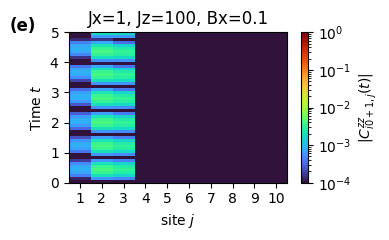

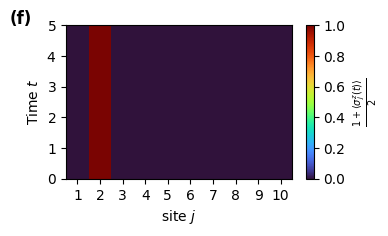

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
from matplotlib.ticker import ScalarFormatter

# -------------------------
# FORMATTING & SETUP
# -------------------------
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# Create output directory
plot_dir = "plt"
os.makedirs(plot_dir, exist_ok=True)

savefig = True
valuesList = [1]

for value in valuesList:
    # -------------------------
    # SETTINGS & PATHS
    # -------------------------
    outdir = "ED_Data/Confinement/"
    i0 = 1
    t_max_plot = 1000
    alpha = 0
    N = 10
    Bx = 0.1
    Jx = 1
    Jz = 100

    vmin_corr = 1e-4
    prefix = f"Bx{Bx}Jz{Jz}"

    # -------------------------
    # LOAD DATA
    # -------------------------
    df_xx   = pd.read_csv(f"{outdir}/{prefix}corrxx.csv")
    df_zz   = pd.read_csv(f"{outdir}/{prefix}corrzz.csv")
    df_magx = pd.read_csv(f"{outdir}/{prefix}magx.csv")
    df_magz = pd.read_csv(f"{outdir}/{prefix}magz.csv")

    # -------------------------
    # DATA PROCESSING FUNCTIONS
    # -------------------------
    t = df_xx["t"].values
    mask = t <= t_max_plot
    t_plot = t[mask]
    t_min, t_max = t_plot.min(), t_plot.max()

    def build_matrix(df, prefix_str, is_corr=True):
        cols = [c for c in df.columns if c.startswith(prefix_str)]
        if len(cols) == 0:
            raise ValueError(f"No columns found for {prefix_str}")
        
        # Sort by site index j
        j_vals = np.array([int(c.split("_")[-1]) for c in cols])
        order = np.argsort(j_vals)
        
        mat = df[cols].values[:, order]
        if is_corr:
            mat = np.abs(mat)
            mat = np.clip(mat, vmin_corr, 1.0)
        
        return mat[mask, :], j_vals[order]

    # Process matrices
    CorrXX, _ = build_matrix(df_xx, f"Cxx_{i0}_", is_corr=True)
    CorrZZ, _ = build_matrix(df_zz, f"Czz_{i0}_", is_corr=True)
    MagX, _   = build_matrix(df_magx, "mx_", is_corr=False)
    MagZ, _   = build_matrix(df_magz, "mz_", is_corr=False)

    # Normalize Magnetization (-1,1) → (0,1)
    MagX = (MagX + 1) / 2
    MagZ = (MagZ + 1) / 2

    # -------------------------
    # PLOTTING LOOP
    # -------------------------
    # Configuration list for each panel
    plot_configs = [
        {
            "data": CorrZZ, 
            "title": rf"Jx={Jx}, Jz={Jz}, Bx={Bx}", 
            "label": r"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
            "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
            "fname": "Czz", 
            "letter": "(e)"
        },
        # {
        #     "data": CorrZZ, 
        #     "title": rf"$|C^{{zz}}_{{{i0+1},j}}(t)|$", 
        #     "label": r"$|C^{zz}|$", 
        #     "norm": mcolors.LogNorm(vmin=vmin_corr, vmax=1), 
        #     "fname": "Czz", 
        #     "letter": "(b)"
        # },
        {
            "data": MagZ, 
            "title": r"", 
            "label": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
            "norm": plt.Normalize(0, 1), 
            "fname": "MagZ", 
            "letter": "(f)"
        },
        # {
        #     "data": MagZ, 
        #     "title": r"$\frac{1+\langle \sigma_j^z(t)\rangle}{2}$", 
        #     "label": r"Norm. $\langle \sigma^z \rangle$", 
        #     "norm": plt.Normalize(0, 1), 
        #     "fname": "MagZ", 
        #     "letter": "(d)"
        # }
    ]

    for cfg in plot_configs:
        fig, ax = plt.subplots(figsize=(4, 2.5))
        
        im = ax.imshow(
            cfg["data"],
            origin="lower",
            aspect="auto",
            cmap="turbo",
            interpolation="nearest",
            norm=cfg["norm"],
            extent=[0.5, N + 0.5, t_min, t_max],
        )

        # Panel Lettering
        # x=-0.15 relative to axis width, y=1.1 relative to axis height
        ax.text(-0.15, 1.1, cfg["letter"], transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='top', ha='right')

        ax.set_title(cfg["title"])
        ax.set_ylabel(r"Time $t$")
        ax.set_xlabel(r"site $j$")
        
        # Formatting Axis
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
        ax.set_xticks(np.arange(1, N + 1))
        
        # Colorbar
        plt.colorbar(im, ax=ax, label=cfg["label"])
        plt.tight_layout()

        if savefig:
            full_path = f"{plot_dir}/{prefix}_{cfg['fname']}_i{i0+1}_alpha{alpha}_Jx{Jx}_Bx{Bx}_Jz{Jz}.pdf"
            plt.savefig(full_path, dpi=300, bbox_inches="tight")
        
        # plt.savefig("plt/ConfinementJx1.pdf")
        plt.show()

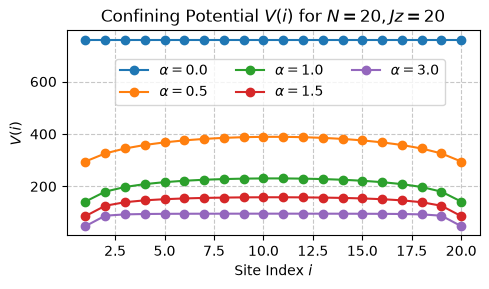

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_V(i, alpha, N, Jx=1.0):
    sites = np.arange(1, N + 1)
    # Exclude the current site i
    others = sites[sites != i]
    # Sum term
    sum_val = np.sum(1.0 / np.abs(i - others)**alpha)
    return 2 * Jx * sum_val

def plot_potentials(N=20, Jx=20.0):
    alphas = [0.0, 0.5, 1.0, 1.5, 3.0]
    sites = np.arange(1, N + 1)
    
    plt.figure(figsize=(5, 3))
    
    for alpha in alphas:
        V_vals = [calculate_V(i, alpha, N, Jx) for i in sites]
        plt.plot(sites, V_vals, marker='o', label=f'$\\alpha = {alpha}$')
    
    plt.title(f'Confining Potential $V(i)$ for $N={N}, Jz=20$')
    plt.xlabel('Site Index $i$')
    plt.ylabel('$V(i)$')
    plt.legend(ncol=3, bbox_to_anchor=(0.1, 0.6), frameon=True)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('plt/confining_potential_alpha.pdf')
    plt.show()

plot_potentials()


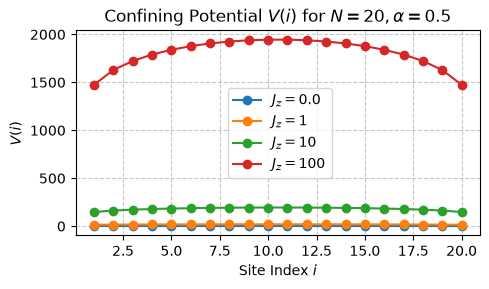

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_V(i, N, Jx, alpha=0.5):
    """
    Calculates the effective potential at site i.
    Fixed order of arguments: non-default arguments must come first.
    """
    sites = np.arange(1, N + 1)
    # Exclude the current site i
    others = sites[sites != i]
    # Sum term
    sum_val = np.sum(1.0 / np.abs(i - others)**alpha)
    return 2 * Jx * sum_val

def plot_potentials(N=20, alpha=0.5):
    Jx_list = [0.0, 1, 10, 100]
    sites = np.arange(1, N + 1)
    
    plt.figure(figsize=(5, 3))
    
    for J in Jx_list:
        V_vals = [calculate_V(i, N, J, alpha) for i in sites]
        # Fixed legend label to show Jx value
        plt.plot(sites, V_vals, marker='o', label=f'$J_z = {J}$')
    
    plt.title(f'Confining Potential $V(i)$ for $N={N}, \\alpha={alpha}$')
    plt.xlabel('Site Index $i$')
    plt.ylabel('$V(i)$')
    plt.legend(ncol=1, bbox_to_anchor=(0.65, 0.5), frameon=True)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('plt/confining_potential_Jz.pdf')
    plt.show()

plot_potentials()